In [6]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [7]:
url = "https://archive-api.open-meteo.com/v1/archive"
params = {
    "latitude": 16.43,
    "longitude": 80.57,
    "start_date": "2025-01-01",
    "end_date": "2025-12-31",
    "daily": ["temperature_2m_max", "temperature_2m_min", "precipitation_sum", "windspeed_10m_max"],
    "timezone": "Asia/Kolkata"
}

response = requests.get(url, params=params)
print("Status:", response.status_code)

data = response.json()
df = pd.DataFrame(data["daily"])
df.head()

Status: 200


,time,temperature_2m_max,temperature_2m_min,precipitation_sum,windspeed_10m_max
0,2025-01-01,31.1,20.9,0.0,9.4
1,2025-01-02,30.2,20.7,0.0,11.2
2,2025-01-03,30.1,20.1,0.0,9.7
3,2025-01-04,30.4,18.8,0.0,10.3
4,2025-01-05,30.2,18.9,0.0,11.9


In [8]:
# Columns peru easy ga marchadam
df.columns = ["date", "temp_max", "temp_min", "rainfall", "wind_max"]

# Date column ni proper date format ki marchadam
df["date"] = pd.to_datetime(df["date"])

# Data info chudadam
print(df.info())
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicates:", df.duplicated().sum())

# Cleaning
df = df.drop_duplicates()
df = df.fillna(df.mean(numeric_only=True))

# Kotta columns add cheyadam
df["temp_avg"] = (df["temp_max"] + df["temp_min"]) / 2
df["month"] = df["date"].dt.month_name()
df["month_num"] = df["date"].dt.month

df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   date      365 non-null    datetime64[ns]
 1   temp_max  365 non-null    float64       
 2   temp_min  365 non-null    float64       
 3   rainfall  365 non-null    float64       
 4   wind_max  365 non-null    float64       
dtypes: datetime64[ns](1), float64(4)
memory usage: 14.4 KB
None

Missing values:
 date        0
temp_max    0
temp_min    0
rainfall    0
wind_max    0
dtype: int64

Duplicates: 0


,date,temp_max,temp_min,rainfall,wind_max,temp_avg,month,month_num
0,2025-01-01,31.1,20.9,0.0,9.4,26.00,January,1
1,2025-01-02,30.2,20.7,0.0,11.2,25.45,January,1
2,2025-01-03,30.1,20.1,0.0,9.7,25.10,January,1
3,2025-01-04,30.4,18.8,0.0,10.3,24.60,January,1
4,2025-01-05,30.2,18.9,0.0,11.9,24.55,January,1


In [9]:
# Basic statistics
print("Basic Statistics:")
print(df[["temp_max", "temp_min", "rainfall", "wind_max"]].describe())

# Hottest and coldest day
hottest = df.loc[df["temp_max"].idxmax()]
coldest = df.loc[df["temp_min"].idxmin()]
print("\nHottest day:", hottest["date"].date(), "->", hottest["temp_max"], "°C")
print("Coldest day:", coldest["date"].date(), "->", coldest["temp_min"], "°C")

# Rainiest day
rainiest = df.loc[df["rainfall"].idxmax()]
print("Rainiest day:", rainiest["date"].date(), "->", rainiest["rainfall"], "mm")

# Total rainy days
print("Total rainy days:", (df["rainfall"] > 0).sum())

# Monthly summary
monthly = df.groupby(["month_num", "month"]).agg(
    avg_temp=("temp_avg", "mean"),
    max_temp=("temp_max", "max"),
    total_rain=("rainfall", "sum")
).reset_index().round(2)

monthly

Basic Statistics:
         temp_max    temp_min    rainfall    wind_max
count  365.000000  365.000000  365.000000  365.000000
mean    33.884932   24.116438    3.466849   15.784658
std      3.129410    2.946558    7.752580    4.402326
min     26.200000   16.300000    0.000000    6.900000
25%     31.400000   22.200000    0.000000   12.500000
50%     33.700000   24.800000    0.200000   15.800000
75%     36.500000   26.100000    3.500000   18.500000
max     40.800000   30.100000   67.000000   35.600000

Hottest day: 2025-05-13 -> 40.8 °C
Coldest day: 2025-12-12 -> 16.3 °C
Rainiest day: 2025-08-13 -> 67.0 mm
Total rainy days: 200


,month_num,month,avg_temp,max_temp,total_rain
0,1,January,25.58,34.3,0.0
1,2,February,28.98,37.7,0.5
2,3,March,31.11,40.7,3.2
3,4,April,31.91,39.9,41.1
4,5,May,31.53,40.8,180.8
5,6,June,31.74,39.4,101.3
6,7,July,30.36,37.9,140.9
7,8,August,29.35,36.8,275.9
8,9,September,28.70,35.4,178.2
9,10,October,27.53,34.1,294.3


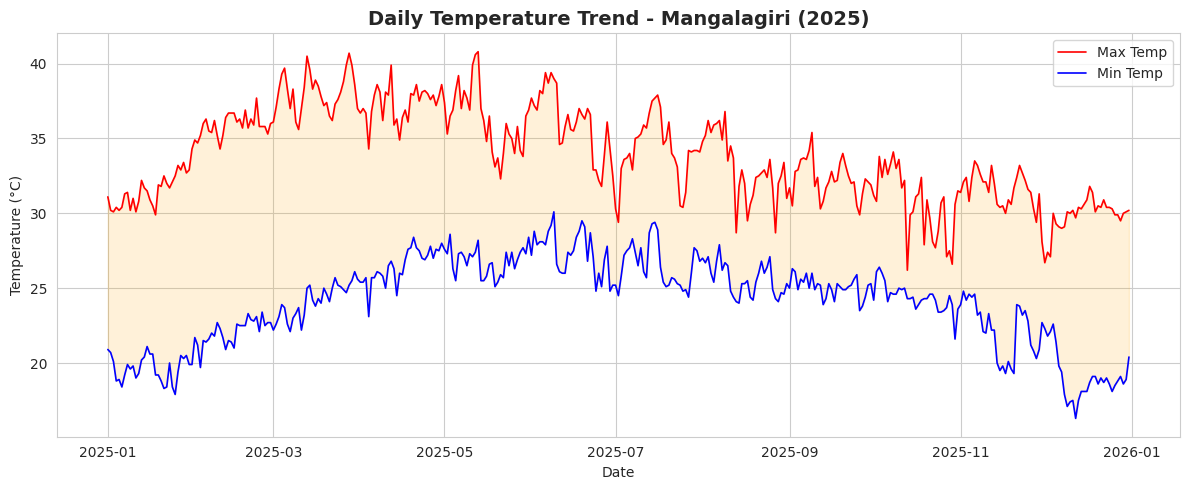

In [10]:
plt.figure(figsize=(12, 5))
plt.plot(df["date"], df["temp_max"], label="Max Temp", color="red", linewidth=1.2)
plt.plot(df["date"], df["temp_min"], label="Min Temp", color="blue", linewidth=1.2)
plt.fill_between(df["date"], df["temp_min"], df["temp_max"], color="orange", alpha=0.15)

plt.title("Daily Temperature Trend - Mangalagiri (2025)", fontsize=14, fontweight="bold")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.tight_layout()
plt.show()

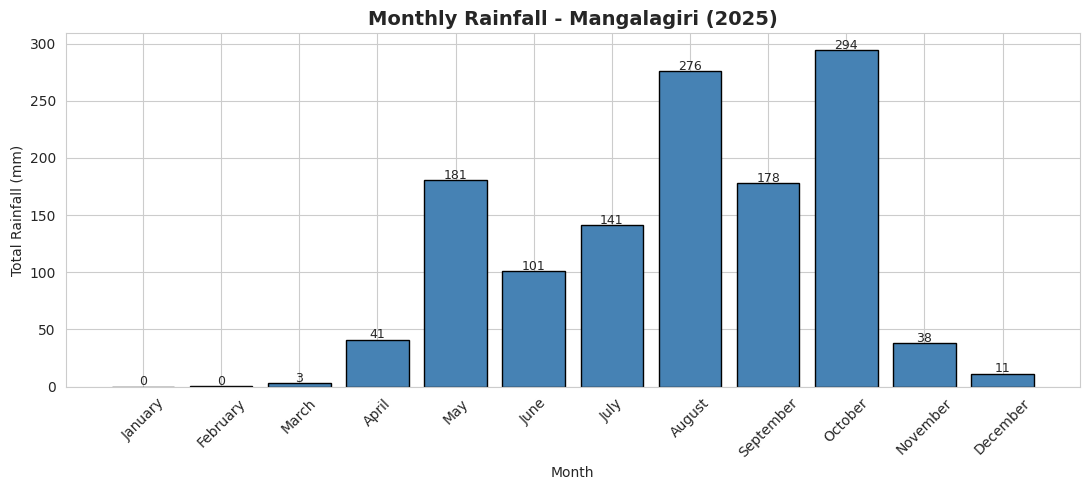

In [11]:
plt.figure(figsize=(11, 5))

bars = plt.bar(monthly["month"], monthly["total_rain"], color="steelblue", edgecolor="black")

# Bar meeda values chupinchadam
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 1, f"{height:.0f}",
             ha="center", fontsize=9)

plt.title("Monthly Rainfall - Mangalagiri (2025)", fontsize=14, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Total Rainfall (mm)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


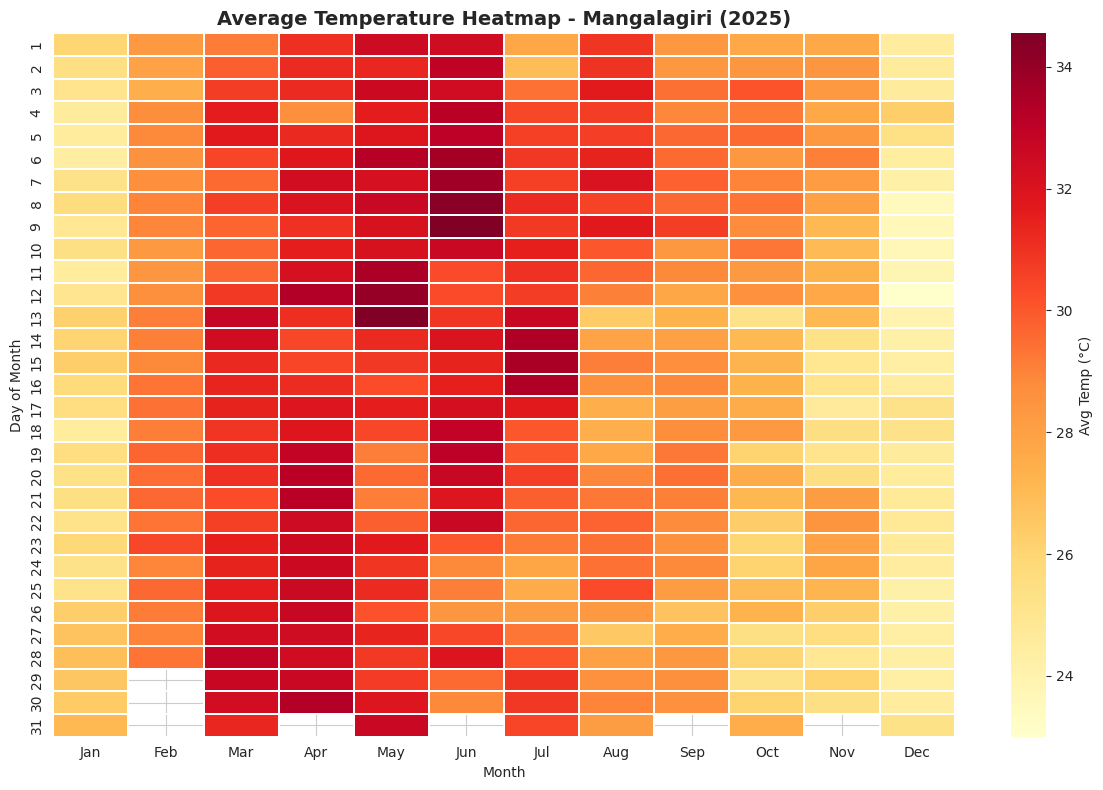

In [12]:
# Rows = day of month, Columns = month
pivot = df.pivot_table(values="temp_avg",
                       index=df["date"].dt.day,
                       columns="month_num")

pivot.columns = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                 "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.figure(figsize=(12, 8))
sns.heatmap(pivot, cmap="YlOrRd", linewidths=0.3, cbar_kws={"label": "Avg Temp (°C)"})

plt.title("Average Temperature Heatmap - Mangalagiri (2025)", fontsize=14, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Day of Month")
plt.tight_layout()
plt.show()


In [13]:
df.to_csv("weather_cleaned.csv", index=False)
monthly.to_csv("monthly_summary.csv", index=False)

hottest_month = monthly.loc[monthly["avg_temp"].idxmax(), "month"]
rainiest_month = monthly.loc[monthly["total_rain"].idxmax(), "month"]
coolest_month = monthly.loc[monthly["avg_temp"].idxmin(), "month"]

print("Hottest month  :", hottest_month)
print("Coolest month  :", coolest_month)
print("Rainiest month :", rainiest_month)
print("Total rainfall :", round(df["rainfall"].sum(), 1), "mm")

Hottest month  : April
Coolest month  : December
Rainiest month : October
Total rainfall : 1265.4 mm
